# 02 – Modélisation

Ce notebook couvre les axes 4 (développement du modèle) et 5 (choix des métriques).

Étapes :
1. découpage train / test ;
2. choix des métriques ;
3. références à battre (baseline et règle actuelle) ;
4. trois modèles réglés en validation croisée ;
5. test du niveau d'études ;
6. diagnostic (sur-apprentissage, importance des variables, erreurs) ;
7. évaluation finale sur le test, une seule fois ;
8. sauvegarde du modèle.

In [1]:
import sys

sys.path.append("..")          

#pour les reglages , le chargement et l'import des données tout en renommant les colonnes ( sans sexe age et situation) 

import json

import warnings

import joblib

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import FunctionTransformer, StandardScaler

from sklearn.dummy import DummyClassifier

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.inspection import permutation_importance

from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

from src.donnees import preparer_donnees, VARIABLES_MODELE, RETARDS, FACTURES, PAIEMENTS, NOUVELLES

# vu que je travaille sur un mac, numpy affiche parfois de faux avertissements pendant la rl
warnings.filterwarnings("ignore", message=".*encountered in matmul")

sns.set_theme(style="whitegrid")

FIGURES = "../reports/figures/"

df = preparer_donnees()      

X = df[VARIABLES_MODELE]     

y = df["defaut"]

print("Dimensions :", X.shape)

print(list(X.columns))

Dimensions : (30000, 22)
['plafond_credit', 'facture_sep', 'facture_aou', 'facture_jul', 'facture_jun', 'facture_mai', 'facture_avr', 'paiement_sep', 'paiement_aou', 'paiement_jul', 'paiement_jun', 'paiement_mai', 'paiement_avr', 'retard_sep', 'retard_aou', 'retard_jul', 'retard_jun', 'retard_mai', 'retard_avr', 'nb_mois_retard', 'taux_utilisation', 'taux_remboursement']


## 1. Découpage train / test

Je garde 20 % des clients (6 000) pour le test. Je ne les utilise qu'à la fin (partie 7), pour évaluer le modèle choisi. Le découpage est stratifié pour garder 22,1 % de défauts dans les deux jeux.

`X` ne contient que les variables du modèle (`VARIABLES_MODELE` dans `src/donnees.py`) : plafond, factures, paiements, retards et les 3 variables construites. L'identifiant, le sexe, l'âge et la situation familiale ne sont jamais utilisés.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# un split 80/20 stratifié, le test est mis de côté jusqu'à la fin

print("Train :", len(X_train), "clients, taux de défaut", round(y_train.mean(), 3))

print("Test  :", len(X_test), "clients, taux de défaut", round(y_test.mean(), 3))

Train : 24000 clients, taux de défaut 0.221
Test  : 6000 clients, taux de défaut 0.221


## 2. Choix des métriques (axe 5)

La décision consiste à classer les clients du plus risqué au moins risqué, puis à appeler les premiers, dans la limite de la capacité de l'équipe. J'ai donc besoin d'une métrique de classement.

- **Métrique principale : ROC-AUC.** Elle mesure si le modèle place bien les défauts avant les non-défauts, sans choisir de seuil. C'est elle qui sert à régler les modèles et à les comparer.
- **Métrique métier : rappel à nombre d'appels égal.** C'est la part des défauts trouvés quand on appelle autant de clients que la règle actuelle. Je la mesure sur le test (partie 7).
- **Suivi : PR-AUC.** Elle est plus sensible à la classe minoritaire (les défauts).
- **Garde-fou : la capacité d'appel.** On n'appelle jamais plus de clients que la règle actuelle (environ 23 % du portefeuille), car l'équipe ne peut pas en traiter plus.
- L'accuracy n'est pas utilisée : on a vu qu'elle atteint 77,9 % sans trouver un seul défaut.

Je n'utilise pas `class_weight="balanced"`. Je veux des probabilités réalistes, parce qu'au notebook 03 je les multiplie par le montant de la facture.

Validation croisée : 5 plis stratifiés, sur le train uniquement.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # validation croisée à 5 plis chacun avec la meme part de défautd

## 3. Références à battre

- **Baseline** : `DummyClassifier`, qui prédit toujours « pas de défaut ». Sa ROC-AUC vaut 0,5 : elle ne sait pas classer.
- **Règle actuelle** : appeler les clients déjà en retard en septembre. Elle n'apprend rien, je l'évalue directement sur le train.

In [4]:
dummy = DummyClassifier(strategy="most_frequent")

scores = cross_val_score(dummy, X_train, y_train, cv=cv, scoring="roc_auc")

print("Baseline : ROC-AUC", round(scores.mean(), 3))

# reférences à battre, la baseline (AUC 0,5) et la regle actuelle

regle_train = X_train["retard_sep"] >= 1

defaut_train = y_train == 1

print("Règle actuelle : ROC-AUC", round(roc_auc_score(y_train, regle_train), 3))

print("Règle actuelle : appelle", round(regle_train.mean() * 100, 1), "% des clients et trouve",
      round((regle_train & defaut_train).sum() / defaut_train.sum() * 100, 1), "% des défauts")

Baseline : ROC-AUC 0.5
Règle actuelle : ROC-AUC 0.688
Règle actuelle : appelle 22.9 % des clients et trouve 52.2 % des défauts


## 4. Trois modèles réglés en validation croisée (axe 4)

Pour chaque modèle, `GridSearchCV` essaie plusieurs réglages en validation croisée (5 plis) et garde celui qui a la meilleure ROC-AUC moyenne.

**Régression logistique** (modèle linéaire). Avant le modèle, je prépare les données dans un `Pipeline` :
- montants (plafond, factures, paiements) : logarithme, car ils sont très asymétriques (notebook 01), puis standardisation ;
- autres variables : standardisation.

La préparation est dans le `Pipeline`, donc elle est refaite dans chaque pli sans voir le pli de validation (pas de fuite). Je règle `C` : plus `C` est petit, plus le modèle est contraint (régularisation).

In [5]:
MONTANTS = ["plafond_credit"] + FACTURES + PAIEMENTS
AUTRES = RETARDS + NOUVELLES

def log_signe(x):
    return np.sign(x) * np.log1p(np.abs(x))

preparation = ColumnTransformer([
    ("montants", Pipeline([("log", FunctionTransformer(log_signe)), ("echelle", StandardScaler())]), MONTANTS),
    ("autres", StandardScaler(), AUTRES),
])
logreg = Pipeline([("prep", preparation), ("clf", LogisticRegression(max_iter=2000))])

recherche_logreg = GridSearchCV(logreg, {"clf__C": [0.001, 0.003, 0.01, 0.03, 0.1, 1]},
                                scoring="roc_auc", cv=cv, return_train_score=True)
recherche_logreg.fit(X_train, y_train)

print("Régression logistique, meilleur réglage :", recherche_logreg.best_params_)
# Régression logistique (que j'abrege avec rl) : log + standardisation dans un Pipeline (pas de fuite), C réglé par GridSearchCV

Régression logistique, meilleur réglage : {'clf__C': 0.003}


**Arbre de décision et Random Forest.** Les arbres n'ont pas besoin de standardisation : je les utilise directement. Je règle la profondeur (`max_depth`) et le nombre minimal de clients par feuille (`min_samples_leaf`). La Random Forest utilise 200 arbres.

In [6]:
recherche_arbre = GridSearchCV(DecisionTreeClassifier(random_state=42),
                               {"max_depth": [4, 6, 8, 10, 12], "min_samples_leaf": [200, 400, 800]},
                               scoring="roc_auc", cv=cv, return_train_score=True)
recherche_arbre.fit(X_train, y_train)

print("Arbre, meilleur réglage :", recherche_arbre.best_params_)

recherche_foret = GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
                               {"max_depth": [6, 10, 14, None], "min_samples_leaf": [20, 50, 100]},
                               scoring="roc_auc", cv=cv, return_train_score=True)
recherche_foret.fit(X_train, y_train)

print("Random Forest, meilleur réglage :", recherche_foret.best_params_)
# arbre et Random Forest, reglage de la profondeur et du nombre minimal de clients par feuille

Arbre, meilleur réglage : {'max_depth': 8, 'min_samples_leaf': 400}
Random Forest, meilleur réglage : {'max_depth': 14, 'min_samples_leaf': 50}


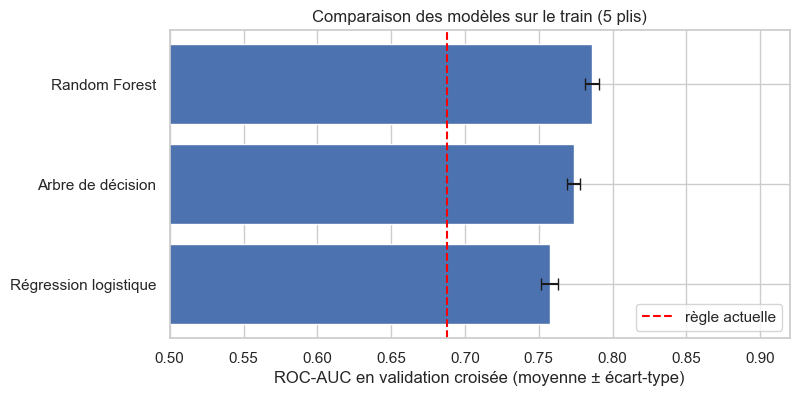

,meilleur réglage,AUC train,AUC validation,écart-type
modèle,,,,
Régression logistique,{'clf__C': 0.003},0.759,0.758,0.006
Arbre de décision,"{'max_depth': 8, 'min_samples_leaf': 400}",0.790,0.774,0.004
Random Forest,"{'max_depth': 14, 'min_samples_leaf': 50}",0.835,0.786,0.005


In [7]:
lignes = []
for nom, recherche in [("Régression logistique", recherche_logreg),
                       ("Arbre de décision", recherche_arbre),
                       ("Random Forest", recherche_foret)]:
    i = recherche.best_index_          
    lignes.append({
        "modèle": nom,
        "meilleur réglage": recherche.best_params_,
        "AUC train": recherche.cv_results_["mean_train_score"][i],
        "AUC validation": recherche.cv_results_["mean_test_score"][i],
        "écart-type": recherche.cv_results_["std_test_score"][i],
    })
comparaison = pd.DataFrame(lignes).set_index("modèle")

#pour comparer entre les 3 modèles : AUC moyenne et écart-type en validation croisée

plt.figure(figsize=(8, 4))

plt.barh(comparaison.index, comparaison["AUC validation"], xerr=comparaison["écart-type"], capsize=4)

plt.axvline(roc_auc_score(y_train, regle_train), color="red", linestyle="--", label="règle actuelle")

plt.xlim(0.5, 0.92)

plt.xlabel("ROC-AUC en validation croisée (moyenne ± écart-type)")

plt.title("Comparaison des modèles sur le train (5 plis)")


plt.legend(loc="lower right")

plt.savefig(FIGURES + "comparaison modeles.png", dpi=150, bbox_inches="tight")

plt.show()

comparaison.round(3)

Les trois modèles battent la baseline (0,5) et la règle actuelle (0,69). La Random Forest est la meilleure : ROC-AUC de 0,786 en validation croisée, contre 0,774 pour l'arbre et 0,758 pour la régression logistique. Les écarts entre les modèles sont plus grands que les écarts-types (environ 0,005) : ils ne viennent pas du hasard du découpage.

Je retiens la Random Forest. Elle est moins lisible qu'une régression logistique, donc j'explique ses choix avec l'importance des variables (partie 6).

## 5. Le niveau d'études apporte-t-il quelque chose ?

Au notebook 01, j'ai laissé cette question ouverte. Je compare la Random Forest retenue avec et sans `education`.

In [8]:
foret = recherche_foret.best_estimator_ #le random forest

# le niveau d'études améliore-t-il le modèle ? Comparaison avec et sans

X_train_edu = X_train.copy()

X_train_edu["education"] = df.loc[X_train.index, "education"]

sans = cross_val_score(foret, X_train, y_train, cv=cv, scoring="roc_auc")

avec = cross_val_score(foret, X_train_edu, y_train, cv=cv, scoring="roc_auc")

print("Sans education : ROC-AUC", round(sans.mean(), 4), "±", round(sans.std(), 4))

print("Avec education : ROC-AUC", round(avec.mean(), 4), "±", round(avec.std(), 4))

Sans education : ROC-AUC 0.7863 ± 0.0047
Avec education : ROC-AUC 0.786 ± 0.0043


Le niveau d'études ne change rien (ROC-AUC de 0,786 dans les deux cas). Je ne le garde pas : il n'apporte rien, et c'est une variable sociale de moins dans la décision.

## 6. Diagnostic

### 6.1 Sur-apprentissage : effet de la profondeur

Je reprends les résultats de la recherche par grille de la Random Forest : pour chaque profondeur, je compare l'AUC sur le train et en validation.

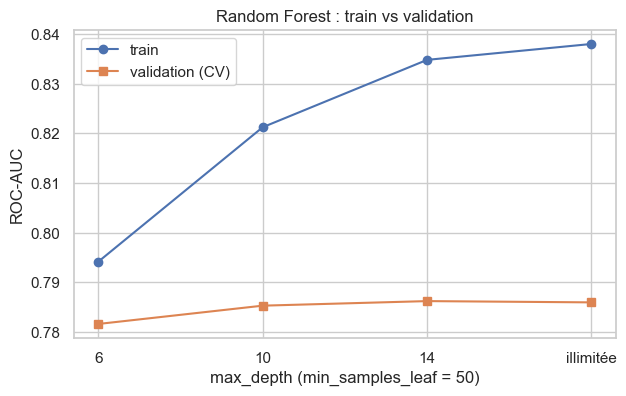

,param_max_depth,mean_train_score,mean_test_score
1,6,0.794,0.782
4,10,0.821,0.785
7,14,0.835,0.786
10,None,0.838,0.786


In [9]:
resultats = pd.DataFrame(recherche_foret.cv_results_)

feuille = recherche_foret.best_params_["min_samples_leaf"]

courbe = resultats[resultats["param_min_samples_leaf"] == feuille]

profondeurs = ["6", "10", "14", "illimitée"]          

# sur-apprentissage  AUC train contre validation selon la profondeur

plt.figure(figsize=(7, 4))

plt.plot(profondeurs, courbe["mean_train_score"], "o-", label="train")

plt.plot(profondeurs, courbe["mean_test_score"], "s-", label="validation (CV)")

plt.xlabel(f"max_depth (min_samples_leaf = {feuille})")

plt.ylabel("ROC-AUC")

plt.title("Random Forest : train vs validation")

plt.legend()

plt.savefig(FIGURES + "surapprentissage.png", dpi=150, bbox_inches="tight")

plt.show()

courbe[["param_max_depth", "mean_train_score", "mean_test_score"]].round(3)

Plus les arbres sont profonds, plus l'AUC sur le train monte (de 0,79 à 0,84), mais l'AUC en validation plafonne vers 0,786 dès 10 niveaux. L'écart entre train et validation pour le modèle retenu (0,835 contre 0,786) montre un peu de sur-apprentissage. Il reste limité grâce aux feuilles d'au moins 50 clients, et c'est le réglage qui donne la meilleure validation.

### 6.2 Importance des variables et analyse des erreurs

Pour ce diagnostic, je mets de côté 20 % du train comme jeu de validation. J'entraîne la Random Forest sur le reste, puis :
- je mesure l'importance de chaque variable par permutation : on mélange une variable et on regarde de combien l'AUC baisse ;
- j'étudie les défauts que le modèle rate quand on appelle 22,7 % des clients (comme la règle).

Le jeu de test n'est toujours pas utilisé.

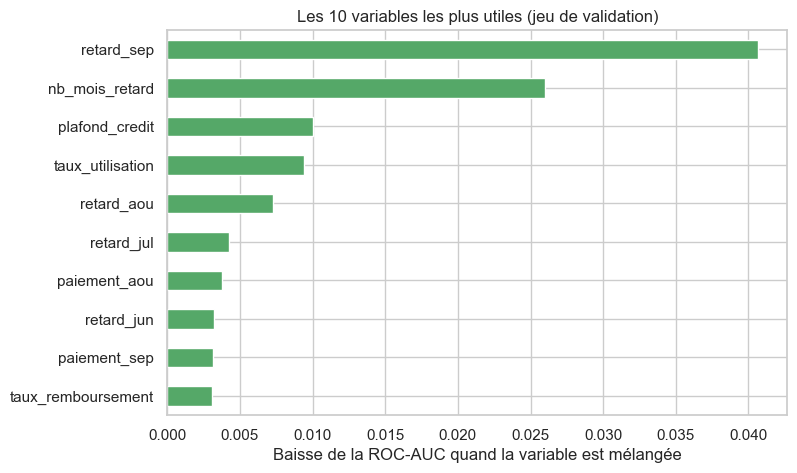

retard_sep            0.0406
nb_mois_retard        0.0260
plafond_credit        0.0100
taux_utilisation      0.0094
retard_aou            0.0073
retard_jul            0.0043
paiement_aou          0.0037
retard_jun            0.0032
paiement_sep          0.0031
taux_remboursement    0.0031
dtype: float64

In [10]:
X_fit, X_valid, y_fit, y_valid = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

modele_diag = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1,
                                     max_depth=recherche_foret.best_params_["max_depth"],
                                     min_samples_leaf=recherche_foret.best_params_["min_samples_leaf"])
modele_diag.fit(X_fit, y_fit)

resultat = permutation_importance(modele_diag, X_valid, y_valid, scoring="roc_auc",
                                  n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.Series(resultat.importances_mean, index=X_valid.columns).sort_values(ascending=False)

importance.head(10).sort_values().plot(kind="barh", color="#55A868", figsize=(8, 5))

plt.xlabel("Baisse de la ROC-AUC quand la variable est mélangée")

plt.title("Les 10 variables les plus utiles (jeu de validation)")

plt.savefig(FIGURES + "importance variables.png", dpi=150, bbox_inches="tight")

plt.show()

importance.head(10).round(4)

#l'importance des variables par permutation, sur une partie du train et non sur le teste

Le retard de septembre et le nombre de mois en retard sont de loin les variables les plus utiles. Viennent ensuite le plafond et le taux d'utilisation. Les factures et les paiements comptent peu. Pour un conseiller, le motif d'appel est donc simple à expliquer : des retards récents ou répétés, un petit plafond (on a vu au notebook 01 que le risque baisse quand le plafond augmente), une carte utilisée près de sa limite.

In [11]:
proba_valid = modele_diag.predict_proba(X_valid)[:, 1]

appele = proba_valid >= np.quantile(proba_valid, 1 - 0.227)     

defaut = (y_valid == 1).values

trouves = X_valid[appele & defaut]

manques = X_valid[~appele & defaut]

print("Défauts trouvés :", len(trouves), "| défauts manqués :", len(manques))

print("Défauts manqués sans aucun retard sur 6 mois :", round((manques["nb_mois_retard"] == 0).mean() * 100), "%")

#l'analyse des erreurs , défauts trouvés contre défauts manqués, en appelant 22,7 % des clients (soit environ 23% comme j'indiquerai dans le Readme)

colonnes = ["nb_mois_retard", "retard_sep", "taux_utilisation", "taux_remboursement", "plafond_credit", "facture_sep"]

pd.DataFrame({"défauts trouvés (médiane)": trouves[colonnes].median(),
              "défauts manqués (médiane)": manques[colonnes].median()}).round(3)

Défauts trouvés : 583 | défauts manqués : 479
Défauts manqués sans aucun retard sur 6 mois : 78 %


,défauts trouvés (médiane),défauts manqués (médiane)
nb_mois_retard,3.000,0.000
retard_sep,2.000,0.000
taux_utilisation,0.610,0.315
taux_remboursement,0.049,0.133
plafond_credit,70000.000,130000.000
facture_sep,24166.000,17243.000


Sur le jeu de validation, le modèle trouve 583 défauts et en rate 479. 78 % des défauts ratés concernent des clients sans aucun retard sur les 6 derniers mois, avec un plafond plus élevé et une carte moins utilisée. Ces clients ressemblent aux bons clients : leur historique de paiement ne permet pas de les repérer. C'est une limite du modèle. Pour faire mieux, il faudrait d'autres informations (revenus, autres crédits), absentes de ce jeu de données.

## 7. Évaluation finale sur le test (une seule fois)

Le modèle retenu est la Random Forest avec le meilleur réglage. `GridSearchCV` l'a déjà ré-entraînée sur tout le train. Je l'évalue maintenant sur les 6 000 clients du test, et je la compare à la règle actuelle avec le même nombre d'appels.

In [12]:
modele_final = recherche_foret.best_estimator_

proba_test = modele_final.predict_proba(X_test)[:, 1]

regle_test = (X_test["retard_sep"] >= 1).values

defaut_test = (y_test == 1).values

part = regle_test.mean()

appele_test = proba_test >= np.quantile(proba_test, 1 - part)

def resultats(appele, score):
    return {"clients appelés": appele.mean(),
            "ROC-AUC": roc_auc_score(defaut_test, score),
            "PR-AUC": average_precision_score(defaut_test, score),
            "défauts trouvés (rappel)": (appele & defaut_test).sum() / defaut_test.sum(),
            "appels utiles (précision)": (appele & defaut_test).sum() / appele.sum()}

resultats_test = pd.DataFrame({"Règle actuelle": resultats(regle_test, regle_test.astype(float)),
                               "Random Forest": resultats(appele_test, proba_test)}).T
resultats_test.round(3)

#evaluation finale sur le test, une seule fois, avec autant d'appels que la regle

,clients appelés,ROC-AUC,PR-AUC,défauts trouvés (rappel),appels utiles (précision)
Règle actuelle,0.221,0.678,0.359,0.497,0.498
Random Forest,0.221,0.778,0.557,0.539,0.540


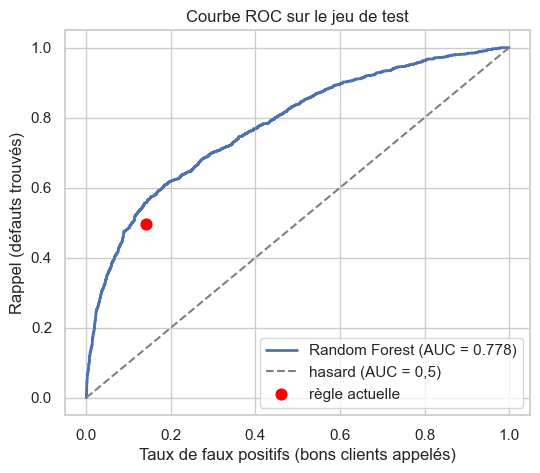

In [13]:
fpr, tpr, _ = roc_curve(defaut_test, proba_test)

fpr_regle = (regle_test & ~defaut_test).sum() / (~defaut_test).sum()

tpr_regle = (regle_test & defaut_test).sum() / defaut_test.sum()

plt.figure(figsize=(6, 5))

plt.plot(fpr, tpr, lw=2, label=f"Random Forest (AUC = {roc_auc_score(defaut_test, proba_test):.3f})")

plt.plot([0, 1], [0, 1], "--", color="gray", label="hasard (AUC = 0,5)")

plt.scatter([fpr_regle], [tpr_regle], color="red", s=60, zorder=3, label="règle actuelle")

plt.xlabel("Taux de faux positifs (bons clients appelés)")

plt.ylabel("Rappel (défauts trouvés)")

plt.title("Courbe ROC sur le jeu de test")

plt.legend(loc="lower right")

plt.savefig(FIGURES + "courbe roc test.png", dpi=150, bbox_inches="tight")

plt.show()

#la courbe ROC sur le test, avec le point de la regle actuelle

Sur le test, la Random Forest a une ROC-AUC de 0,778, proche de la validation croisée (0,786) : pas de mauvaise surprise. Avec le même nombre d'appels que la règle (22,1 % des clients du test), elle trouve 53,9 % des défauts contre 49,7 % pour la règle, et ses appels sont plus souvent utiles (54,0 % contre 49,8 %). Sur la courbe ROC, le point rouge (la règle) est sous la courbe du modèle : à nombre d'appels égal, le modèle fait mieux.

## 8. Sauvegarde

Je sauvegarde le modèle et les chiffres clés. Le notebook 03 les réutilise.

In [14]:
import os

os.makedirs("../models", exist_ok=True)         

joblib.dump(modele_final, "../models/modele_final.joblib")

metriques = {
    "modele": "Random Forest",
    "reglage": str(recherche_foret.best_params_),
    "auc_validation": round(comparaison.loc["Random Forest", "AUC validation"], 4),
    "auc_test": round(resultats_test.loc["Random Forest", "ROC-AUC"], 4),
    "rappel_test_modele": round(resultats_test.loc["Random Forest", "défauts trouvés (rappel)"], 4),
    "rappel_test_regle": round(resultats_test.loc["Règle actuelle", "défauts trouvés (rappel)"], 4),
}
with open("../reports/metriques_modele.json", "w", encoding="utf-8") as f:
    json.dump(metriques, f, indent=2, ensure_ascii=False)
metriques

#la sauvegarde du modèle (que je vais utiliser dans le notebook 03) et des métriques

{'modele': 'Random Forest',
 'reglage': "{'max_depth': 14, 'min_samples_leaf': 50}",
 'auc_validation': np.float64(0.7863),
 'auc_test': np.float64(0.7775),
 'rappel_test_modele': np.float64(0.5388),
 'rappel_test_regle': np.float64(0.4974)}

## Résumé

- Modèle retenu : Random Forest (200 arbres, `max_depth` = 14, `min_samples_leaf` = 50).
- ROC-AUC : 0,786 ± 0,005 en validation croisée, 0,778 sur le test. Règle actuelle : 0,678 sur le test.
- À nombre d'appels égal, le modèle trouve 54 % des défauts du test, contre 50 % pour la règle.
- Variables les plus utiles : les retards (septembre et nombre de mois), puis le plafond et le taux d'utilisation.
- Niveau d'études retiré : il n'apporte rien.
- Limite : les défauts de clients sans aucun retard passé restent difficiles à repérer.
- Suite (notebook 03) : utiliser la probabilité et le montant de la facture pour choisir qui appeler, puis chiffrer les coûts et le ROI.